# Step 5b — DistilBERT cross-encoder

Step 4's ESIM with DistilBERT as the encoder: one joined row `[CLS] A [SEP] B [SEP]` (A = Overture first), masked mean + max pooling over the row, MLP 200 (tanh) → 1 logit.

Spec: `step5_spec.md`.

In [1]:
# Colab only (does nothing locally): mount Google Drive and work from the project's copy there.
# After this, every relative path (sys.path "..", load_pairs, CHECKPOINT_DIR = "checkpoints") points into Drive,
# so checkpoints survive a disconnect.
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/geocoding_ml/transformers")
    print("Colab: working in", os.getcwd())
except ImportError:
    pass

## 1. Setup

In [2]:
import sys
sys.path.append("..")   # geocoding_ml/ -> lets us import from helpers/
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from helpers.pairs import load_pairs
from siamese_model.data_plumbing import PairDataset
from torch.utils.data import DataLoader, Dataset, Subset
from torch import nn
import os, copy
from helpers.check_model_performance import review_typical_slices   # slice table used by evaluate
# only these four: real_training's own train_epoch / predict are Step 3's CPU versions
from siamese_model.real_training import is_better, broken_run_problems, THRESHOLD, CASE1_GUARDRAIL


DATASET = "overture_case2s"
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available()          # Colab GPU
                      else "mps" if torch.backends.mps.is_available()  # M1 Pro
                      else "cpu")
BATCH_SIZE = 32
MLP_HIDDEN, DROPOUT = 200, 0.3   # head, as in ESIM
MAX_EPOCHS = 5
PATIENCE = 2
SEEDS = [0, 1, 2]
CHECKPOINT_DIR = "checkpoints_cross"   # git-ignored; its own folder so 5a's seed files are never skipped or resumed

train, train_label = load_pairs(DATASET, "train")
val, val_label = load_pairs(DATASET, "val")
test, test_label = load_pairs(DATASET, "test")
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
train.shape, val.shape, test.shape, DEVICE

/Users/david/Downloads/ml-geocoding/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/david/Downloads/ml-geocoding/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


((202568, 8), (41865, 8), (43844, 8), device(type='mps'))

## 2. Tokenise + collate

Pairs tokenised together: `tok(address_a, address_b, ...)`, `padding=True`, `max_length=MAX_LENGTH`.

In [3]:
def make_collate():
    def collate(samples):
        addr_a, addr_b, labels = zip(*samples)
        lengths = torch.tensor([len(x) for x in tok(addr_a, addr_b)["input_ids"]])

        ids = tok(addr_a, addr_b, padding=True, return_tensors="pt")
        mask = (
            torch.arange(lengths.max())[None, :] < lengths[:, None]).long()
        
        assert torch.equal(mask, ids["attention_mask"])
        y = torch.tensor(labels, dtype=torch.float32)
        return ids["input_ids"], mask, y 
    return collate


train_dataset = PairDataset(train, train_label)
val_dataset = PairDataset(val, val_label)
test_dataset = PairDataset(test, test_label)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle = True, collate_fn = make_collate())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle = False, collate_fn= make_collate())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle = False, collate_fn= make_collate())

In [31]:
ids, mask, y = next(iter(train_loader))
assert ((ids == tok.sep_token_id).sum(1) == 2).all()
assert tok.decode(ids[0]).startswith("[CLS]")
assert (mask.sum(1) == (ids != tok.pad_token_id).sum(1)).all()

## 3. Encoder: DistilBERT + masked mean + max pooling

Tests directly under the class.

In [6]:
class MeanMaxPooling(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, h, mask):
        m = mask.unsqueeze(-1).bool()  # (B, T, 1), True = real token; broadcasts over features
        mean_pool = (h * m).sum(1) / m.sum(1) # pads add 0 and don't count: (B, T, D) -> (B, D)
        max_pool = h.masked_fill(~m, float("-inf")).max(dim=1).values
        return torch.cat([mean_pool, max_pool], dim = 1)


class BertEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = MeanMaxPooling()
        self.bert = AutoModel.from_pretrained(MODEL_NAME)
        self.output_dim = 2 * self.bert.config.hidden_size

    def forward(self,ids, mask):
        bert_res = self.bert(input_ids=ids, attention_mask=mask)
        return self.pool(bert_res.last_hidden_state, mask)

In [37]:
h = torch.tensor([[[1., 1.], [9., 9.]]])   # 1 row, 2 positions; position 2 is a pad
mask = torch.tensor([[1, 0]])
assert torch.equal(MeanMaxPooling()(h, mask), torch.tensor([[1., 1., 1., 1.]]))

## 4. Cross-encoder: head + forward

MLP 200, tanh, dropout per spec. Tests directly under the class.

In [7]:
class ClassifierHead(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear1 = nn.Linear(input_dim, MLP_HIDDEN) 
        self.tanh = nn.Tanh()
        self.dropout = nn.Dropout(DROPOUT)
        self.linear2 = nn.Linear(MLP_HIDDEN, 1)
        

    def forward(self, vectors):
        linear1_val = self.linear1(vectors)
        tanh_val = self.tanh(linear1_val)
        dropout_val = self.dropout(tanh_val)
        linear2_val = self.linear2(dropout_val)
        return linear2_val.squeeze(-1)

# ESIM model
class CrossEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = BertEncoder()
        self.head = ClassifierHead(self.encoder.output_dim)

    def forward(self, ids, mask):
        res = self.encoder(ids, mask)    
        return self.head(res)

## 5. Optimiser + scheduler

AdamW, two groups: encoder 2e-5, head 1e-3; weight decay 0.01; 10% linear warm-up.

In [8]:
model = CrossEncoder()
N_EPOCHS = 10
optimizer = torch.optim.AdamW([
    {"params": model.encoder.parameters(), "lr": 2e-5},
    {"params": model.head.parameters(),    "lr": 1e-3},
], weight_decay=0.01)

total_steps = len(train_loader) * N_EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)

## 6. Timing: one epoch on a 10k train slice

Batch 32, on `DEVICE`. Decides epoch budget and M1 Pro vs Colab.

In [10]:
def to_device(batch):
    return (t.to(DEVICE) for t in batch)                             # all three tensors: ids, mask, y

def sync():
    # GPUs run asynchronously: wait until the queued work is done before reading the clock
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()

def train_epoch(model, loader, opt, sched, loss_fn):
    model.train()
    total_loss, n_pairs = 0.0, 0
    for batch in loader:
        ids, mask, y = to_device(batch)
        opt.zero_grad()                                              # first: clear anything left from before
        logits = model(ids, mask)                                    # the model never sees y
        loss = loss_fn(logits, y)                                    # BCEWithLogitsLoss applies the sigmoid itself
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)   # between backward and step: edits the gradients step uses
        opt.step()
        sched.step()                                                 # after opt.step(): sets the lr for the next batch
        total_loss += loss.item() * len(y)                           # weight by batch size -> average per pair, not per batch
        n_pairs += len(y)
    return total_loss / n_pairs

def predict(model, loader):
    model.eval()
    probs = []
    with torch.no_grad():                                            # no graph recorded, no updates
        for batch in loader:
            ids, mask, y = to_device(batch)                          # y unused
            logits = model(ids, mask)
            probs.append(torch.sigmoid(logits).cpu())                # logits -> probabilities, back on the CPU
    return torch.cat(probs)                                          # (N,), in loader order: val/test loaders must not shuffle

In [46]:
import time
SEED = 0
N_TIMING_BATCHES = 200

torch.manual_seed(SEED)
timing_model = CrossEncoder().to(DEVICE)
timing_opt = torch.optim.AdamW([
    {"params": timing_model.encoder.parameters(), "lr": 2e-5},
    {"params": timing_model.head.parameters(),    "lr": 1e-3},
], weight_decay=0.01)
timing_steps = N_TIMING_BATCHES  # one pass over the timing slice
timing_sched = get_linear_schedule_with_warmup(
    timing_opt, num_warmup_steps=int(0.1 * timing_steps), num_training_steps=timing_steps)

# random rows: the first train rows are short identical positives and would understate the time
rng = np.random.default_rng(SEED)
timing_idx = rng.choice(len(train_dataset), N_TIMING_BATCHES * BATCH_SIZE, replace=False)
subset_loader = DataLoader(Subset(train_dataset, timing_idx), batch_size=BATCH_SIZE, collate_fn=make_collate())

# train/val loaders come from §2 (train shuffled); don't rebuild them here

t0 = time.perf_counter()
train_epoch(timing_model, subset_loader, timing_opt, timing_sched, nn.BCEWithLogitsLoss())
sync()
train_seconds = time.perf_counter() - t0
print(f"train: {train_seconds / N_TIMING_BATCHES:.3f} s/batch -> {train_seconds / N_TIMING_BATCHES * len(train_loader) / 60:.1f} min/epoch")

t0 = time.perf_counter()
predict(timing_model, val_loader)
sync()
print(f"val pass: {time.perf_counter() - t0:.1f} s")

del timing_model, timing_opt, timing_sched
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
elif DEVICE.type == "mps":
    torch.mps.empty_cache()

train: 0.153 s/batch -> 16.1 min/epoch
val pass: 35.3 s


## 7. Training

Best epoch = highest val non-identical found with val case1 ≥ 98%.

In [48]:
def evaluate(model, loader, df, labels):
    """Copied from siamese_model/real_training.py; calls this notebook's device-aware predict."""
    probs = predict(model, loader)
    y_true = torch.tensor(labels.values, dtype=torch.float32)
    preds = (probs >= THRESHOLD).int().numpy()
    val_loss = nn.functional.binary_cross_entropy(probs, y_true).item()
    table = review_typical_slices(df, preds, labels).set_index("slice")
    pct = lambda name: float(100 * table.loc[name, "correct"] / table.loc[name, "n"])
    found = pct("positives: non-identical")
    case1 = pct("neg: case1 (same street, diff number)")
    easy = pct("neg: case3 (easy)")
    return {"val_loss": val_loss, "found": found, "case1": case1, "easy": easy}


def run_training(seed, train_loader=train_loader, checkpoint_dir=CHECKPOINT_DIR, max_epochs=MAX_EPOCHS):
    # train_loader / checkpoint_dir / max_epochs are arguments so the dry run can't leave a global changed
    torch.manual_seed(seed)
    last_path = f"{checkpoint_dir}/seed_{seed}_last.pt"
    final_path = f"{checkpoint_dir}/seed_{seed}_final.pt"

    model = CrossEncoder().to(DEVICE)
    model.train()
    opt = torch.optim.AdamW([
        {"params": model.encoder.parameters(), "lr": 2e-5},
        {"params": model.head.parameters(),    "lr": 1e-3},
    ], weight_decay=0.01)
    total_steps = len(train_loader) * max_epochs
    sched = get_linear_schedule_with_warmup(
        opt, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)
    loss_fn = nn.BCEWithLogitsLoss()

    best, best_state, history = None, None, []
    epochs_since_best, start_epoch = 0, 0
    
    if os.path.exists(last_path):                      # a disconnected run: continue after its last finished epoch
        ck = torch.load(last_path, map_location=DEVICE)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        history, best, best_state, epochs_since_best = ck["history"], ck["best"], ck["best_state"], ck["epochs_since_best"]
        start_epoch = ck["epoch"] + 1
        print(f"seed {seed}: resuming at epoch {start_epoch}")
    
    for epoch in range(start_epoch, max_epochs):
        train_loss = train_epoch(model, train_loader, opt,sched, loss_fn)
        
        row = {"epoch": epoch, "train_loss": train_loss,"lr_encoder": sched.get_last_lr()[0], **evaluate(model, val_loader, val, val_label)}
        print(row)
        history.append(row)

        

        if is_better(row, best):
            best, best_state, epochs_since_best = row, copy.deepcopy(model.state_dict()), 0
        else:
            epochs_since_best += 1
            if epochs_since_best >= PATIENCE:
                break

        state = {
            "epoch": epoch, "model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), 
            "history": history, "best": best,
            "best_state": best_state, "epochs_since_best": epochs_since_best,
        }
        torch.save(state, last_path + ".tmp")
        os.replace(last_path + ".tmp", last_path)
        
    # no epoch reached the case1 guardrail -> keep the last epoch's weights
    if best is None:
        best_state = copy.deepcopy(model.state_dict())
    
    torch.save({"seed": seed, "best_state": best_state, "best": best, "history": history}, final_path)
    
    if os.path.exists(last_path):
        os.remove(last_path)

    return pd.DataFrame(history), best, best_state

In [50]:
import shutil
dry_loader = DataLoader(Subset(train_dataset, range(64)), batch_size = 8, shuffle = True, collate_fn = make_collate())
os.makedirs("checkpoints_dry", exist_ok = True)   # git-ignored, in case the run crashes before the cleanup
dry_history, dry_best, dry_best_state= run_training(0, dry_loader, "checkpoints_dry", max_epochs = 2)
display(dry_history)   # not the last line -> needs display()

shutil.rmtree("checkpoints_dry")   # os.remove only deletes files, not folders


{'epoch': 0, 'train_loss': 0.2060471724398667, 'lr_encoder': 1.0666666666666667e-05, 'val_loss': 5.959127902984619, 'found': 100.0, 'case1': 0.0, 'easy': 0.0}
{'epoch': 1, 'train_loss': 0.001106647338019684, 'lr_encoder': 0.0, 'val_loss': 6.191230297088623, 'found': 100.0, 'case1': 0.0, 'easy': 0.0}


,epoch,train_loss,lr_encoder,val_loss,found,case1,easy
0,0,0.206047,0.000011,5.959128,100.0,0.0,0.0
1,1,0.001107,0.000000,6.191230,100.0,0.0,0.0


In [51]:

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
for seed in SEEDS:
    if os.path.exists(f"{CHECKPOINT_DIR}/seed_{seed}_final.pt"):
        print(f"seed {seed}: already finished, skipping")
        continue
    history, best, best_state = run_training(seed)
    print(seed, broken_run_problems(history))

{'epoch': 0, 'train_loss': 0.055513869508720365, 'lr_encoder': 1.777746577746578e-05, 'val_loss': 0.032574720680713654, 'found': 71.14178168130489, 'case1': 99.93469269283797, 'easy': 99.99564630589055}
{'epoch': 1, 'train_loss': 0.028676954462670698, 'lr_encoder': 1.3333099333099335e-05, 'val_loss': 0.026632575318217278, 'found': 63.237139272271015, 'case1': 99.96371816268775, 'easy': 100.0}
{'epoch': 2, 'train_loss': 0.02365139311037619, 'lr_encoder': 8.88873288873289e-06, 'val_loss': 0.032066710293293, 'found': 73.27478042659975, 'case1': 99.89115448806328, 'easy': 99.98693891767165}
{'epoch': 3, 'train_loss': 0.01929914065255638, 'lr_encoder': 4.444366444366445e-06, 'val_loss': 0.029790982604026794, 'found': 74.27854454203262, 'case1': 99.94194906030042, 'easy': 99.99564630589055}
{'epoch': 4, 'train_loss': 0.015735004941846993, 'lr_encoder': 0.0, 'val_loss': 0.02960079535841942, 'found': 77.66624843161857, 'case1': 99.89115448806328, 'easy': 99.98693891767165}
0 []
{'epoch': 0, 't

## 8. Results

Slice table on val, then test; rare-number case1 group. Swap test deferred.

Cells below written by Claude 2026-11-12 at David's request (same structure as 5a §8); David runs them. Order: run health → predictions (saves `preds_*` / `probs_*`, once) → slice tables → AUC by house-number group.

In [4]:
# Run health + best epoch per seed.
# Pass: problems == [] and best epoch < MAX_EPOCHS - 1 (else 5 epochs was too few).
for seed in SEEDS:
    ck = torch.load(f"{CHECKPOINT_DIR}/seed_{seed}_final.pt", map_location="cpu", weights_only=False)
    h = pd.DataFrame(ck["history"])
    print(f"--- seed {seed}: problems {broken_run_problems(h)}, best epoch {ck['best']['epoch'] if ck['best'] else None}, epochs run {len(h)}")
    display(h.round(4))

--- seed 0: problems [], best epoch 4, epochs run 5


,epoch,train_loss,lr_encoder,val_loss,found,case1,easy
0,0,0.0555,0.0,0.0326,71.1418,99.9347,99.9956
1,1,0.0287,0.0,0.0266,63.2371,99.9637,100.0000
2,2,0.0237,0.0,0.0321,73.2748,99.8912,99.9869
3,3,0.0193,0.0,0.0298,74.2785,99.9419,99.9956
4,4,0.0157,0.0,0.0296,77.6662,99.8912,99.9869


--- seed 1: problems [], best epoch 1, epochs run 4


,epoch,train_loss,lr_encoder,val_loss,found,case1,easy
0,0,0.0572,0.0,0.0345,78.1681,99.7097,99.9913
1,1,0.0275,0.0,0.0314,78.7955,99.8766,99.9913
2,2,0.0215,0.0,0.0267,77.4153,99.9202,99.9826
3,3,0.0183,0.0,0.0304,78.6700,99.9274,99.9782


--- seed 2: problems [], best epoch 1, epochs run 4


,epoch,train_loss,lr_encoder,val_loss,found,case1,easy
0,0,0.0573,0.0,0.0329,72.6474,99.9202,100.0000
1,1,0.0288,0.0,0.0323,76.9134,99.7243,99.9826
2,2,0.0239,0.0,0.0318,76.0351,99.9057,99.9869
3,3,0.0198,0.0,0.0298,76.6625,99.8839,99.9782


In [11]:
# One forward pass per seed and split: probabilities saved, predictions = probs >= THRESHOLD.
# Written once; a re-run loads the files instead of recomputing.
import itertools

splits = {"val": (val_loader, val, val_label), "test": (test_loader, test, test_label)}

for seed, phase in itertools.product(SEEDS, splits):
    loader, df, labels = splits[phase]
    probs_path = os.path.join(CHECKPOINT_DIR, f"probs_{phase}_seed_{seed}.npy")
    preds_path = os.path.join(CHECKPOINT_DIR, f"preds_{phase}_seed_{seed}.npy")   # name esim_diagnostics reads
    if not os.path.exists(probs_path):
        model = CrossEncoder().to(DEVICE)
        ck = torch.load(f"{CHECKPOINT_DIR}/seed_{seed}_final.pt", map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["best_state"])
        np.save(probs_path, predict(model, loader).numpy())
    probs = np.load(probs_path)
    preds = (probs >= THRESHOLD).astype(int)
    np.save(preds_path, preds)
    assert len(preds) == len(df)
    print(seed, phase)
    display(review_typical_slices(df, preds, labels))

0 val


,slice,n,correct,errors,% correct
0,positives: identical,3390,3390,0,100.0%
1,positives: non-identical,797,619,178,77.7%
2,"neg: case1 (same street, diff number)",13781,13766,15,99.9%
3,"neg: case2 (same number, similar street)",34,20,14,58.8%
4,neg: case3 (easy),22969,22966,3,100.0%
5,neg: case2s (swapped look-alike street),894,815,79,91.2%
6,overall (accuracy),41865,41576,289,99.3%


0 test


,slice,n,correct,errors,% correct
0,positives: identical,3543,3543,0,100.0%
1,positives: non-identical,843,596,247,70.7%
2,"neg: case1 (same street, diff number)",14448,14440,8,99.9%
3,"neg: case2 (same number, similar street)",15,6,9,40.0%
4,neg: case3 (easy),23942,23940,2,100.0%
5,neg: case2s (swapped look-alike street),1053,942,111,89.5%
6,overall (accuracy),43844,43467,377,99.1%


1 val


,slice,n,correct,errors,% correct
0,positives: identical,3390,3390,0,100.0%
1,positives: non-identical,797,628,169,78.8%
2,"neg: case1 (same street, diff number)",13781,13764,17,99.9%
3,"neg: case2 (same number, similar street)",34,22,12,64.7%
4,neg: case3 (easy),22969,22967,2,100.0%
5,neg: case2s (swapped look-alike street),894,760,134,85.0%
6,overall (accuracy),41865,41531,334,99.2%


... (2 outputs left out)

2 val


,slice,n,correct,errors,% correct
0,positives: identical,3390,3390,0,100.0%
1,positives: non-identical,797,613,184,76.9%
2,"neg: case1 (same street, diff number)",13781,13743,38,99.7%
3,"neg: case2 (same number, similar street)",34,23,11,67.6%
4,neg: case3 (easy),22969,22965,4,100.0%
5,neg: case2s (swapped look-alike street),894,796,98,89.0%
6,overall (accuracy),41865,41530,335,99.2%


2 test


,slice,n,correct,errors,% correct
0,positives: identical,3543,3543,0,100.0%
1,positives: non-identical,843,592,251,70.2%
2,"neg: case1 (same street, diff number)",14448,14410,38,99.7%
3,"neg: case2 (same number, similar street)",15,8,7,53.3%
4,neg: case3 (easy),23942,23941,1,100.0%
5,neg: case2s (swapped look-alike street),1053,978,75,92.9%
6,overall (accuracy),43844,43472,372,99.2%


In [12]:
# Sanity check: val predictions must reproduce the found / case1 stored in final.pt's best row
# (silent failure otherwise: wrong weights loaded, or loader order differs from training's evaluate).
for seed in SEEDS:
    best = torch.load(f"{CHECKPOINT_DIR}/seed_{seed}_final.pt", map_location="cpu", weights_only=False)["best"]
    t = review_typical_slices(val, np.load(f"{CHECKPOINT_DIR}/preds_val_seed_{seed}.npy"), val_label).set_index("slice")
    pct = lambda n: float(100 * t.loc[n, "correct"] / t.loc[n, "n"])
    found, case1 = pct("positives: non-identical"), pct("neg: case1 (same street, diff number)")
    print(f"seed {seed}: found {found:.4f} vs {best['found']:.4f}, case1 {case1:.4f} vs {best['case1']:.4f}")

seed 0: found 77.6662 vs 77.6662, case1 99.8912 vs 99.8912
seed 1: found 78.7955 vs 78.7955, case1 99.8766 vs 99.8766
seed 2: found 76.9134 vs 76.9134, case1 99.7243 vs 99.7243


In [15]:
# 5b next to 5a and ESIM rand_mc2: same pairs, same slice code.
from esim.esim_diagnostics import slice_table, rare_number_table
S = {"5a": "checkpoints", "5b": CHECKPOINT_DIR, "rand_mc2": "../esim/checkpoints/esim_rand_mc2"}
for name, (df, labels) in {"val": (val, val_label), "test": (test, test_label)}.items():
    print(name)
    display(slice_table(df, labels, name, settings=S))
display(rare_number_table({"val": (val, val_label), "test": (test, test_label)}, settings=S,
                          w2v_path="../esim/checkpoints/word2vec_50_mc2.model"))

val


5a                      5b  \
                                               0       1       2       0   
slice                                                                      
positives: identical                      100.0%  100.0%  100.0%  100.0%   
positives: non-identical                   85.9%   85.8%   87.2%   77.7%   
neg: case1 (same street, diff number)      99.4%   99.3%   98.9%   99.9%   
neg: case2 (same number, similar street)   47.1%   50.0%   47.1%   58.8%   
neg: case3 (easy)                         100.0%  100.0%  100.0%  100.0%   
neg: case2s (swapped look-alike street)    62.2%   59.5%   62.0%   91.2%   
overall (accuracy)                         98.7%   98.6%   98.5%   99.3%   

                                                         rand_mc2          \
                                               1       2        0       1   
slice                                                                       
positives: identical                      100.0%  100.0%   100.0%  100.0%   
positives: non-identical                   78.8%   76.9%    77.8%   81.8%   
neg: case1 (same street, diff number)      99.9%   99.7%    99.0%   99.0%   
neg: case2 (same number, similar street)   64.7%   67.6%    55.9%   55.9%   
neg: case3 (easy)                         100.0%  100.0%   100.0%  100.0%   
neg: case2s (swapped look-alike street)    85.0%   89.0%    74.6%   76.0%   
overall (accuracy)                         99.2%   99.2%    98.7%   98.8%   

                                                  
                                               2  
slice                                             
positives: identical                      100.0%  
positives: non-identical                   80.3%  
neg: case1 (same street, diff number)      99.2%  
neg: case2 (same number, similar street)   55.9%  
neg: case3 (easy)                         100.0%  
neg: case2s (swapped look-alike street)    82.2%  
overall (accuracy)                         98.9%

test


5a                      5b  \
                                               0       1       2       0   
slice                                                                      
positives: identical                      100.0%  100.0%  100.0%  100.0%   
positives: non-identical                   82.0%   83.0%   83.7%   70.7%   
neg: case1 (same street, diff number)      99.4%   99.3%   99.0%   99.9%   
neg: case2 (same number, similar street)   46.7%   66.7%   26.7%   40.0%   
neg: case3 (easy)                         100.0%  100.0%   99.9%  100.0%   
neg: case2s (swapped look-alike street)    62.9%   58.2%   61.6%   89.5%   
overall (accuracy)                         98.5%   98.4%   98.4%   99.1%   

                                                         rand_mc2          \
                                               1       2        0       1   
slice                                                                       
positives: identical                      100.0%  100.0%    99.9%  100.0%   
positives: non-identical                   73.0%   70.2%    74.9%   78.9%   
neg: case1 (same street, diff number)      99.8%   99.7%    98.9%   98.9%   
neg: case2 (same number, similar street)   46.7%   53.3%    33.3%   26.7%   
neg: case3 (easy)                         100.0%  100.0%   100.0%   99.9%   
neg: case2s (swapped look-alike street)    82.2%   92.9%    72.9%   75.9%   
overall (accuracy)                         99.0%   99.2%    98.4%   98.6%   

                                                 
                                              2  
slice                                            
positives: identical                      99.9%  
positives: non-identical                  78.2%  
neg: case1 (same street, diff number)     98.6%  
neg: case2 (same number, similar street)  46.7%  
neg: case3 (easy)                         99.9%  
neg: case2s (swapped look-alike street)   74.1%  
overall (accuracy)                        98.4%

identical UNK: found case1 UNK: rejected  \
split setting  seed                                            
val   5a       0                 78 / 78           160 / 161   
               1                 78 / 78           158 / 161   
               2                 78 / 78           156 / 161   
      5b       0                 78 / 78           161 / 161   
               1                 78 / 78           161 / 161   
               2                 78 / 78           161 / 161   
      rand_mc2 0                 78 / 78           158 / 161   
               1                 78 / 78           155 / 161   
               2                 78 / 78           154 / 161   
test  5a       0               178 / 178           404 / 404   
               1               178 / 178           403 / 404   
               2               178 / 178           403 / 404   
      5b       0               178 / 178           404 / 404   
               1               178 / 178           403 / 404   
               2               178 / 178           404 / 404   
      rand_mc2 0               178 / 178           385 / 404   
               1               178 / 178           392 / 404   
               2               178 / 178           379 / 404   

                     identical other: missed  case1 other: errors  
split setting  seed                                                
val   5a       0                           0                   87  
               1                           0                   94  
               2                           0                  142  
      5b       0                           0                   15  
               1                           0                   17  
               2                           0                   38  
      rand_mc2 0                           0                  128  
               1                           0                  132  
               2                           0                  100  
test  5a       0                           0                   81  
               1                           0                   97  
               2                           0                  140  
      5b       0                           0                    8  
               1                           0                   23  
               2                           0                   38  
      rand_mc2 0                           3                  143  
               1                           0                  152  
               2                           2                  171

In [14]:
# AUC: non-identical matches vs case2s, split by the house number of the match.
# Groups as in results.md (test: same 638 / missing on one side 164 / different, both present 41).
# Check the printed group sizes against those before reading the AUCs.
from sklearn.metrics import roc_auc_score
from helpers.pairs import add_number_street

def number_groups(df, labels):
    d = add_number_street(df.copy())
    pos = (labels.values == 1) & (d["address_a"] != d["address_b"]).values
    same = (d["number_a"] == d["number_b"]).values
    miss = d["number_missing"].values
    return {"all": pos, "same number": pos & same, "missing one side": pos & miss,
            "different, both present": pos & ~same & ~miss, "all but missing": pos & ~miss}, (d["neg_type"] == "case2s").values

def auc_vs_c2s(p, pm, c2s):
    return roc_auc_score(np.r_[np.ones(pm.sum()), np.zeros(c2s.sum())], np.r_[p[pm], p[c2s]])

folders = {"5a": "checkpoints", "5b": CHECKPOINT_DIR, "rand_mc2": "../esim/checkpoints/esim_rand_mc2"}
for split, (df, labels) in {"val": (val, val_label), "test": (test, test_label)}.items():
    groups, c2s = number_groups(df, labels)
    print(split, {g: int(m.sum()) for g, m in groups.items()}, "case2s", int(c2s.sum()))
    rows = {(name, seed): {g: auc_vs_c2s(np.load(f"{folder}/probs_{split}_seed_{seed}.npy"), m, c2s) for g, m in groups.items()}
            for name, folder in folders.items() for seed in SEEDS}
    display(pd.DataFrame(rows).T.round(3))

val {'all': 797, 'same number': 618, 'missing one side': 144, 'different, both present': 35, 'all but missing': 653} case2s 894


all  same number  missing one side  different, both present  \
5a       0  0.867        0.937             0.546                    0.944   
         1  0.857        0.930             0.524                    0.940   
         2  0.868        0.932             0.580                    0.928   
5b       0  0.906        0.945             0.725                    0.952   
         1  0.899        0.939             0.718                    0.948   
         2  0.886        0.926             0.712                    0.890   
rand_mc2 0  0.856        0.914             0.623                    0.808   
         1  0.862        0.908             0.668                    0.854   
         2  0.878        0.923             0.676                    0.899   

            all but missing  
5a       0            0.938  
         1            0.931  
         2            0.931  
5b       0            0.945  
         1            0.940  
         2            0.924  
rand_mc2 0            0.908  
         1            0.905  
         2            0.922

test {'all': 843, 'same number': 633, 'missing one side': 164, 'different, both present': 46, 'all but missing': 679} case2s 1053


all  same number  missing one side  different, both present  \
5a       0  0.836        0.926             0.460                    0.945   
         1  0.840        0.935             0.448                    0.932   
         2  0.845        0.928             0.497                    0.945   
5b       0  0.888        0.928             0.723                    0.931   
         1  0.877        0.923             0.689                    0.921   
         2  0.887        0.925             0.729                    0.924   
rand_mc2 0  0.815        0.885             0.547                    0.806   
         1  0.837        0.881             0.667                    0.835   
         2  0.842        0.906             0.592                    0.855   

            all but missing  
5a       0            0.927  
         1            0.935  
         2            0.929  
5b       0            0.928  
         1            0.923  
         2            0.925  
rand_mc2 0            0.879  
         1            0.878  
         2            0.903

## Diagnostics

One-off queries and their results (question → result → query).

**D1 (spec David, frame + line bank by Claude 2026-11-12, lines placed by David): each model at its own balanced threshold.** Question: at the threshold Youden's J picks on val (non-identical matches vs `case2s` only, J = tpr − fpr), what do 5a, 5b and ESIM `rand_mc2` find / reject on test? The threshold is frozen per seed and applied once to test; case1 is a check only. Result (written by Claude 2026-11-12 at David's request, from David's reading): at similar `case2s` rejection 5b finds more than 5a (seeds 0/2: 78.4 / 80.7 vs 66.5–68.8); 5a's thresholds sit at 0.986–0.999 because its `case2s` scores spread up to 1, 5b's J is a shallow plateau (drop 0.027–0.054 over 0.16–0.977, about the seed spread), so seed 1's 0.977 is where `argmax` landed. Thresholds aren't comparable across models; report found / rejected.

In [ ]:
from sklearn.metrics import roc_curve

def slice_masks(df, labels):   # copied from 5a's D4
    return {"pos": (labels.values == 1) & (df["address_a"] != df["address_b"]).values,
            "c2s": (df["neg_type"] == "case2s").values, "case1": (df["neg_type"] == "case1").values}

folders = {"5a": "checkpoints", "5b": CHECKPOINT_DIR, "rand_mc2": "../esim/checkpoints/esim_rand_mc2"}
mv, mt = slice_masks(val, val_label), slice_masks(test, test_label)
rows = []
for name, folder in folders.items():
    for seed in SEEDS:
        pt = np.load(f"{folder}/probs_test_seed_{seed}.npy")
        pv = np.load(f"{folder}/probs_val_seed_{seed}.npy")

        s = np.r_[pv[mv["pos"]], pv[mv["c2s"]]]
        y = np.r_[np.ones(mv["pos"].sum()), np.zeros(mv["c2s"].sum())]

        fpr, tpr, thr = roc_curve(y, s)
        t = thr[np.argmax(tpr - fpr)]

        rows.append({"model": name, "seed": seed, "t": t,
             "found": 100 * (pt[mt["pos"]] >= t).mean(),
             "case2s rejected": 100 * (pt[mt["c2s"]] < t).mean(),
             "case1 rejected": 100 * (pt[mt["case1"]] < t).mean()})
             
display(pd.DataFrame(rows).set_index(["model", "seed"]).round(3))



t   found  case2s rejected  case1 rejected
model    seed                                                
5a       0     0.997  68.446           86.990         100.000
         1     0.999  66.548           92.118          99.993
         2     0.986  68.802           87.559          99.986
5b       0     0.101  78.410           84.330          99.211
         1     0.977  69.514           87.179          99.965
         2     0.160  80.664           88.129          98.657
rand_mc2 0     0.288  86.833           62.393          97.017
         1     0.310  87.307           72.650          97.411
         2     0.496  78.173           73.979          98.643

red: positive, blue: negatives
red: positive, blue: negatives


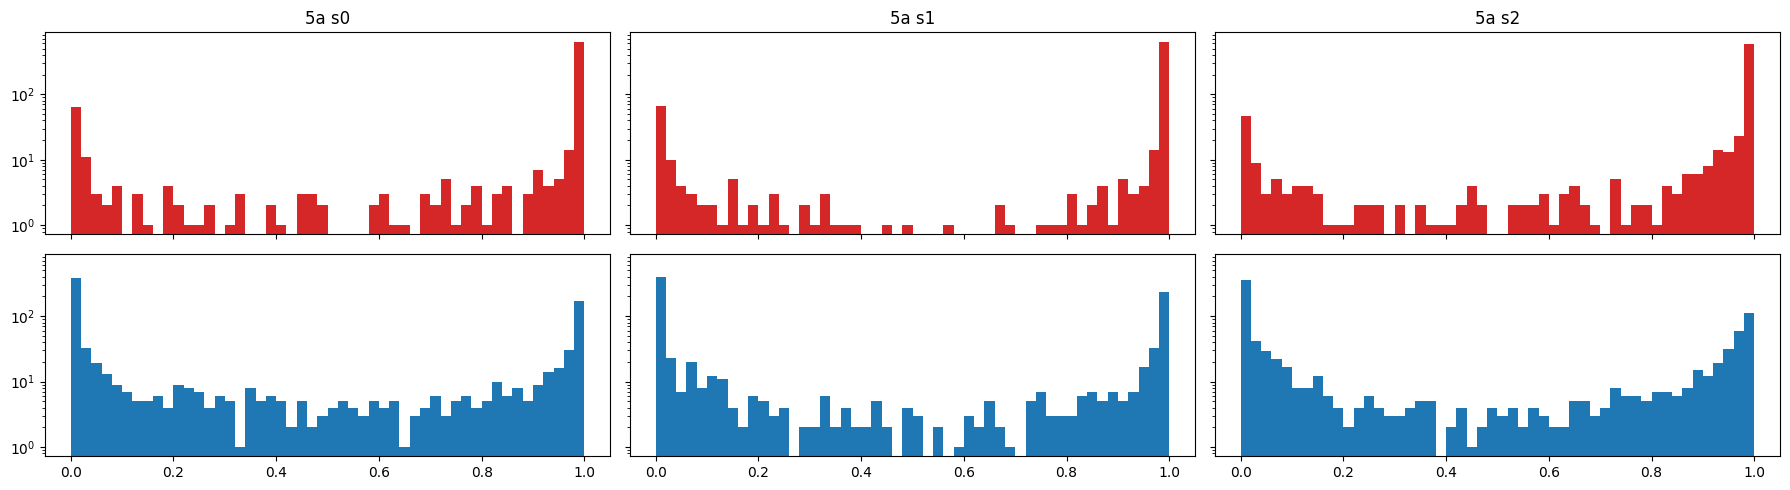

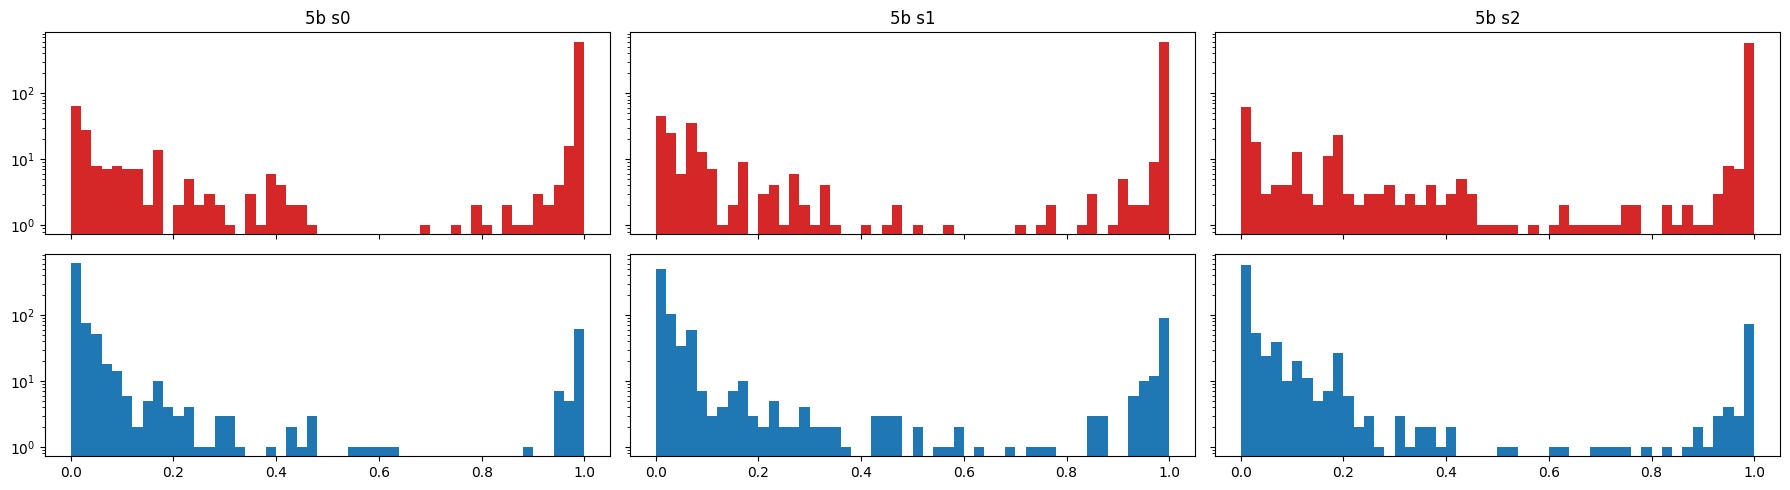

In [ ]:
import matplotlib.pyplot as plt

bins = np.linspace(0, 1, 51)
runs_5a = [(name, seed) for name in ["5a"] for seed in SEEDS]
runs_5b = [(name, seed) for name in ["5b"] for seed in SEEDS]
for runs in [runs_5a, runs_5b]:
    fig, axes = plt.subplots(2, len(runs), sharex=True, sharey=True, figsize=(18, 5))
    for j, (name, seed) in enumerate(runs):
        pv = np.load(f"{folders[name]}/probs_val_seed_{seed}.npy")
        
        axes[0, j].set_title(f"{name} s{seed}")
        axes[1, j].set_yscale("log")
        axes[0, j].set_yscale("log")
        axes[1, j].hist(pv[mv["c2s"]], bins=bins, color="tab:blue")
        axes[0, j].hist(pv[mv["pos"]], bins=bins, color="tab:red")
    print(f"red: positive, blue: negatives")
    plt.tight_layout()






minimum 0.42076972090529646
maximum 0.5787825711069756
minimum 0.419952899435523
maximum 0.543473989429039
minimum 0.45680670523411343
maximum 0.5939863975366235
minimum 0.6725879205858659
maximum 0.7082529844860059
minimum 0.6296332162836589
maximum 0.6561883348911887
minimum 0.636444272285051
maximum 0.6906871124659306


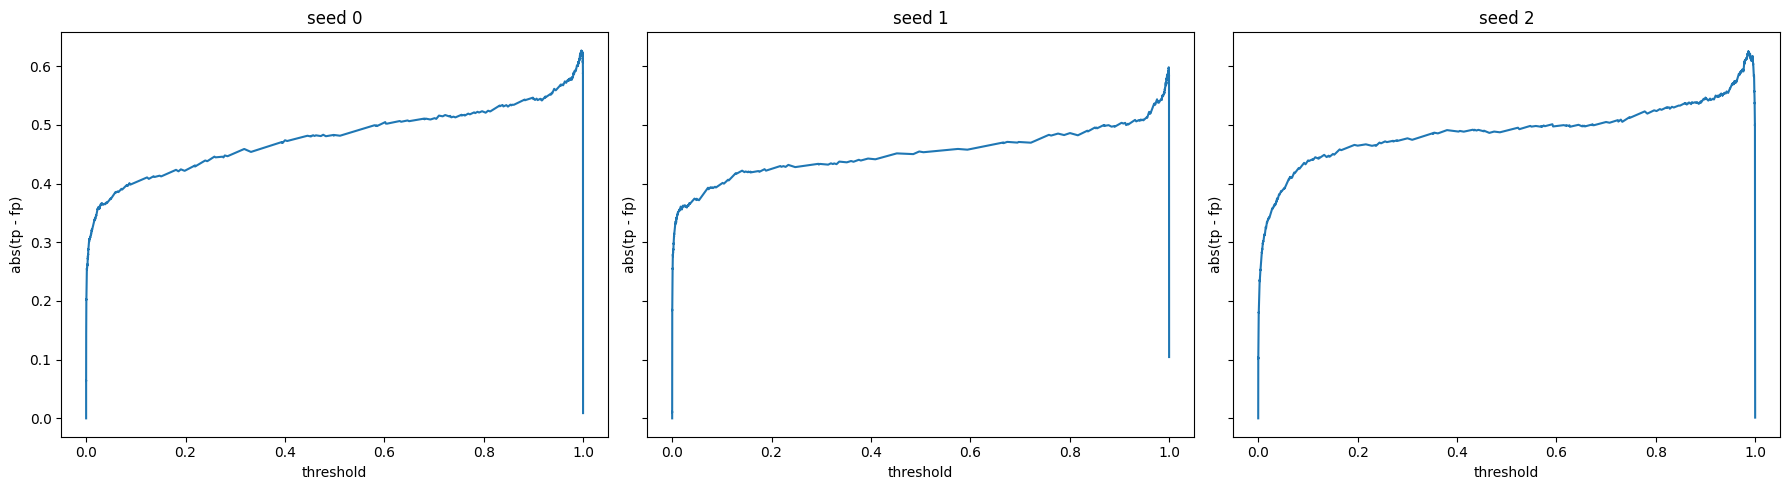

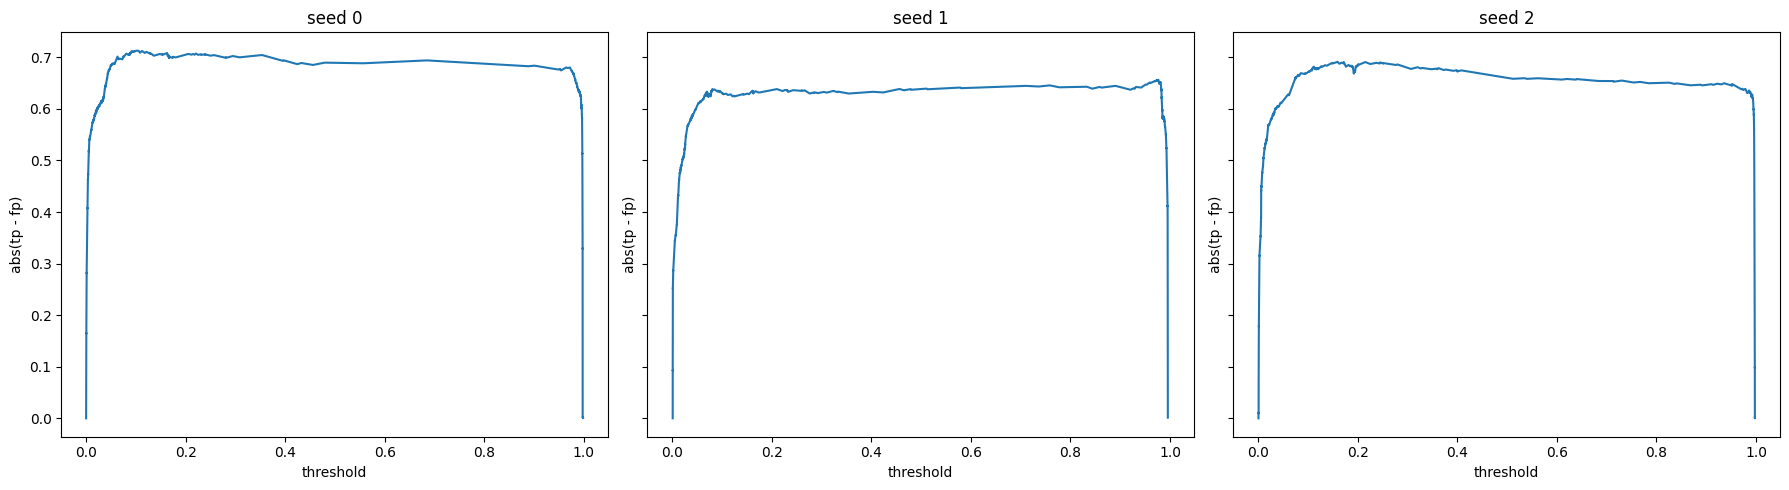

In [33]:
folders = {"5a": "checkpoints","5b": CHECKPOINT_DIR}

for name, folder in folders.items():
    fig, axes = plt.subplots(1, 3, sharex = True, sharey = True, figsize = (18, 5))
    for seed in SEEDS:
        # pt = np.load(f"{folder}/probs_test_seed_{seed}.npy")
        pv = np.load(f"{folder}/probs_val_seed_{seed}.npy")

        s = np.r_[pv[mv["pos"]], pv[mv["c2s"]]]
        y = np.r_[np.ones(mv["pos"].sum()), np.zeros(mv["c2s"].sum())]

        fpr, tpr, thr = roc_curve(y, s)
        t = {th:abs(tp-fp) for fp, tp, th in zip(fpr, tpr, thr)}
        lst = [abs(tp - fp) for fp, tp, th in zip(fpr, tpr, thr) if 0.16 < th < 0.977]
        print("minimum", min(lst))
        print("maximum", max(lst))

        axes[seed].set_title(f"seed {seed}")
        axes[seed].set_ylabel("abs(tp - fp)")
        axes[seed].set_xlabel("threshold")
        axes[seed].plot(list(t.keys()), list(t.values()))
        plt.tight_layout()